# Stage 4: Data Modelling & Analytics

**Financial Forecasting & Variance Analysis** | Stage 4 of 6 | ← [Stage 3: Data Cleaning & Transformation](../03-data-cleaning-and-transformation/03-data-cleaning-and-transformation.ipynb) | [Project README](../../README.md) | [Stage 5: Data Preparation for Reporting](../05-data-preparation-for-reporting/05-data-preparation-for-reporting.ipynb) →

> Build the gold analytical models in SQL, then answer the three research sub-questions: forecasting, variance analysis, and customer value and risk.

| Reads | Writes |
| --- | --- |
| `data/silver/*.parquet` | `data/gold/*.parquet`: SQL models plus forecast, variance and segmentation outputs |

In [1]:
import sys
from pathlib import Path

# Locate the repo root (the folder that holds python/config.py) and import the shared modules
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "python" / "config.py").exists())
sys.path.insert(0, str(ROOT / "python"))

import pandas as pd
import config

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

import numpy as np
from scipy import stats

import warehouse
import forecasting as fc
import segmentation as sg

con = warehouse.connect()

## 4.1 Gold SQL models

| Model | Grain | Purpose |
| --- | --- | --- |
| [`monthly_spend`](../../sql/gold/monthly_spend.sql) | month | Portfolio net spend plus **backward-looking** forecast features |
| [`customer_monthly_variance`](../../sql/gold/customer_monthly_variance.sql) | customer × month | Actual vs a **trailing three-month budget** |
| [`customer_profile`](../../sql/gold/customer_profile.sql) | customer | Behaviour, demographics, cards and fraud exposure, with no double counting |
| [`category_monthly`](../../sql/gold/category_monthly.sql) | MCC × month | Spend and labelled fraud by merchant category |
| [`fraud_profile`](../../sql/gold/fraud_profile.sql) | attribute value | Fraud rate by entry method, channel, card type, hour and so on |

**Corrections compared with the original notebook:**
1. **Feature leakage removed.** The original rolling averages and cumulative revenue included the month being predicted. Every feature window now ends at `1 PRECEDING`.
2. **Variance made non-circular.** The original "budget" was the same month's average, so variances summed to zero by construction. The budget now comes only from earlier months.
3. **Double counting removed.** The original segmentation query joined monthly rows, which repeated each customer's totals once per active month.
4. **Fraud and MCC joins fixed.** The labels and category descriptions are reshaped in silver, so the joins resolve.

In [2]:
GOLD_MODELS = ["monthly_spend", "customer_monthly_variance", "customer_profile",
               "category_monthly", "fraud_profile"]   # monthly_spend first: variance depends on it

pd.DataFrame(
    [{"model": m, "rows": int(warehouse.build_gold(con, m, f"gold/{m}.sql").iloc[0, 0])} for m in GOLD_MODELS]
)

,model,rows
0,monthly_spend,118
1,customer_monthly_variance,136289
2,customer_profile,1219
3,category_monthly,12786
4,fraud_profile,40


## 4.2 Forecasting monthly net spend

### 4.2.1 Series diagnostics

The Augmented Dickey–Fuller test checks whether the series is stationary. If it isn't, differencing is needed, which is why SARIMA has `d=1` and `D=1`. Decomposition separates trend and seasonality, which justifies the seasonal-naive benchmark and the `lag_12` and `month` features.

In [3]:
monthly = fc.prepare(warehouse.query(con, "SELECT * FROM gold_monthly_spend"))
series = monthly[fc.TARGET]

import warnings
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore", message="adfuller currently returns")  # statsmodels return-type notice

def adf(x, label):
    stat, p, *_ = adfuller(x.dropna())
    return {"series": label, "ADF statistic": stat, "p-value": p, "stationary (5%)": p < 0.05}

pd.DataFrame([
    adf(series, "net spend (level)"),
    adf(series.diff(), "first difference"),
    adf(series.diff().diff(12), "first + seasonal difference"),
])

,series,ADF statistic,p-value,stationary (5%)
0,net spend (level),-3.56,0.01,True
1,first difference,-2.58,0.10,False
2,first + seasonal difference,-5.27,0.00,True


Complete months: 118  (Jan 2010 – Oct 2019)
Seasonal strength: 0.95  |  Trend strength: 0.95  (0 = none, 1 = dominant)


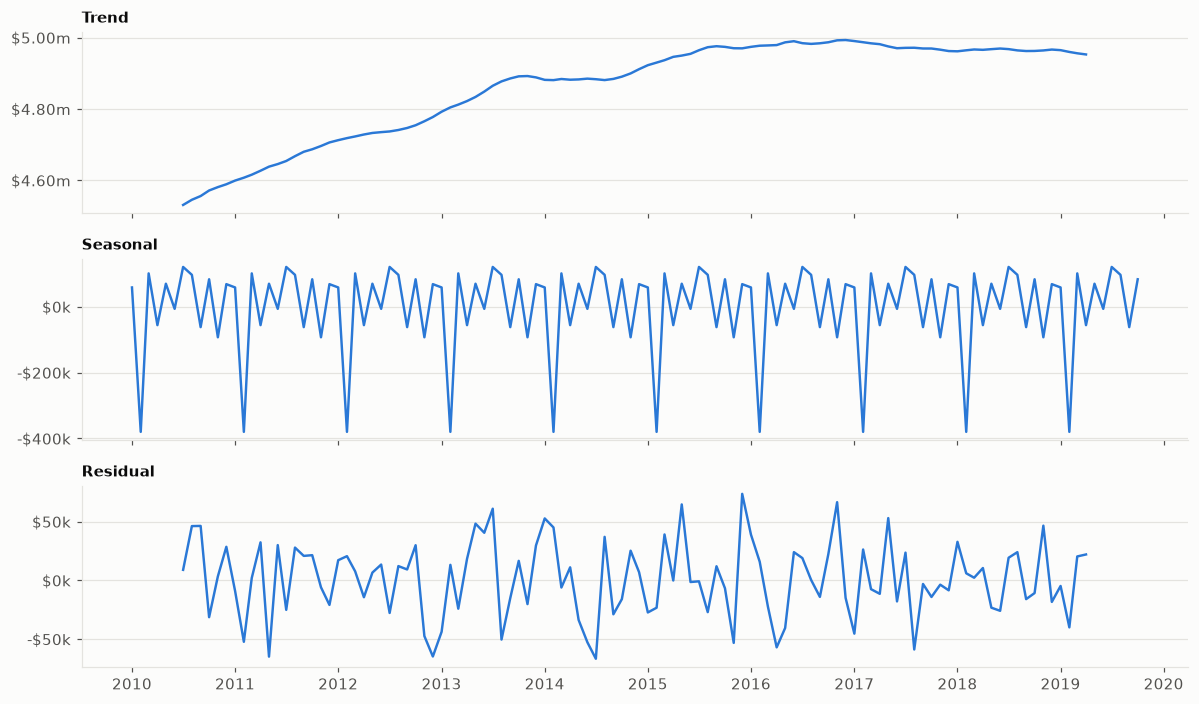

In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose
import charts
charts.apply_style()

decomp = seasonal_decompose(series, model="additive", period=12)
seasonal_strength = 1 - decomp.resid.var() / (decomp.seasonal + decomp.resid).var()
trend_strength = 1 - decomp.resid.var() / (decomp.trend + decomp.resid).var()
print(f"Complete months: {len(series)}  ({series.index.min():%b %Y} – {series.index.max():%b %Y})")
print(f"Seasonal strength: {seasonal_strength:.2f}  |  Trend strength: {trend_strength:.2f}  (0 = none, 1 = dominant)")

fig, axes = charts.plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)
for ax, (name, comp) in zip(axes, [("Trend", decomp.trend), ("Seasonal", decomp.seasonal), ("Residual", decomp.resid)]):
    ax.plot(comp.index, comp, color=charts.SERIES[0], linewidth=1.6)
    charts.money_axis(ax, "y")
    ax.set_title(name, fontsize=10)
charts.show()

### 4.2.2 Walk-forward backtest

There are 24 one-step-ahead forecasts, one for each of the last 24 complete months. Each model is retrained on an **expanding window** of earlier months only, which is how a monthly forecasting process would run in practice. A model is only useful if it beats the seasonal-naive benchmark ("same month last year").

In [5]:
TEST_MONTHS = 24
backtest = fc.walk_forward(monthly, test_months=TEST_MONTHS)
scores = fc.score(backtest)

benchmark_mape = scores.loc[scores["model"].str.startswith("Seasonal naive"), "MAPE_pct"].iloc[0]
scores["MAPE_vs_seasonal_naive_pct"] = (1 - scores["MAPE_pct"] / benchmark_mape) * 100
best_model = scores.iloc[0]["model"]
print(f"Best model by MAPE: {best_model}")
scores

Best model by MAPE: SARIMA


,model,MAE,RMSE,MAPE_pct,R2,MAPE_vs_seasonal_naive_pct
0,SARIMA,"34,701.14","42,037.05",0.70,0.91,0.36
1,Seasonal naive (same month last year),"34,671.56","43,743.79",0.70,0.90,0.00
2,XGBoost,"36,078.27","47,981.44",0.74,0.88,-4.72
3,Naive (last month),"174,439.55","230,547.74",3.56,-1.80,-407.53


### 4.2.3 What drives the XGBoost forecast (SHAP)

The mean absolute SHAP value measures how much each feature moves the prediction, in dollars of net spend. The model is refitted on all usable months for this.

In [6]:
import shap

xgb_model, X_all = fc.final_xgb(monthly)
shap_values = shap.TreeExplainer(xgb_model)(X_all)
importance = (pd.DataFrame({"feature": fc.FEATURES,
                            "mean_abs_shap": np.abs(shap_values.values).mean(axis=0)})
              .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))
importance["share_pct"] = importance["mean_abs_shap"] / importance["mean_abs_shap"].sum() * 100
importance

,feature,mean_abs_shap,share_pct
0,lag_12_month,"94,076.23",48.05
1,rolling_std_6_months,"26,284.33",13.42
2,lag_2_month,"22,432.36",11.46
3,rolling_mean_3_months,"20,565.05",10.50
4,month,"10,685.65",5.46
5,lag_3_month,"9,524.52",4.86
6,lag_1_month,"7,341.07",3.75
7,rolling_mean_6_months,"4,883.74",2.49


### 4.2.4 Forward forecast (12 months, 95% prediction interval)

In [7]:
ahead = fc.forecast_ahead(monthly, horizon=12)
ahead["interval_width_pct"] = (ahead["upper"] - ahead["lower"]) / ahead["forecast"] * 100
ahead

,forecast,lower,upper,interval_width_pct
month_start,,,,
2019-11-01,"4,867,781.20","4,749,102.53","4,986,459.87",4.88
2019-12-01,"4,975,113.92","4,840,858.55","5,109,369.28",5.40
2020-01-01,"4,979,892.05","4,829,146.45","5,130,637.66",6.05
2020-02-01,"4,507,328.20","4,341,973.35","4,672,683.05",7.34
2020-03-01,"5,032,517.62","4,853,719.84","5,211,315.39",7.11
2020-04-01,"4,874,907.54","4,683,611.47","5,066,203.62",7.85
2020-05-01,"5,001,534.28","4,798,507.62","5,204,560.94",8.12
2020-06-01,"4,913,311.90","4,699,196.40","5,127,427.40",8.72
2020-07-01,"5,012,508.16","4,787,850.47","5,237,165.84",8.96


In [8]:
warehouse.write_gold(con, "forecast_backtest", backtest.reset_index())
warehouse.write_gold(con, "forecast_scores", scores)
warehouse.write_gold(con, "forecast_ahead", ahead.reset_index())
warehouse.write_gold(con, "forecast_feature_importance", importance)

## 4.3 Variance analysis: actual vs budget

**Budget** is each customer's average monthly net spend over the previous three months. **Favourable** means spend came in above budget (more portfolio volume) and **Adverse** means it came in below. A variance is **material** when it is at least 10% of budget.

Observations from the same customer are correlated, so the significance test runs at **customer level**: each customer's mean variance is one observation. Spend is heavily right-skewed, so a non-parametric Wilcoxon signed-rank test is reported alongside the t-test.

In [9]:
variance = warehouse.query(con, "SELECT * FROM gold_customer_monthly_variance")

overview = pd.Series({
    "customer-months analysed": len(variance),
    "customers": variance["user_id"].nunique(),
    "favourable %": (variance["variance_type"] == "Favourable").mean() * 100,
    "material %": variance["is_material"].mean() * 100,
    "total actual": variance["actual_spend"].sum(),
    "total budget": variance["budget_spend"].sum(),
    "net variance": variance["variance"].sum(),
    "median variance %": variance["variance_pct"].median(),
}).to_frame("value")
overview

,value
customer-months analysed,"136,289.00"
customers,"1,219.00"
favourable %,47.99
material %,64.71
total actual,"557,798,924.17"
total budget,"557,212,161.51"
net variance,"586,762.66"
median variance %,-1.19


In [10]:
per_customer = variance.groupby("user_id")["variance"].mean()
t_stat, t_p = stats.ttest_1samp(per_customer, 0)
w_stat, w_p = stats.wilcoxon(per_customer)

VAR_TESTS = pd.DataFrame([
    {"test": "One-sample t-test (mean = 0)", "statistic": t_stat, "p_value": t_p},
    {"test": "Wilcoxon signed-rank (median = 0)", "statistic": w_stat, "p_value": w_p},
])
VAR_TESTS["significant_5pct"] = VAR_TESTS["p_value"] < 0.05
print(f"Customer-level mean variance: ${per_customer.mean():,.2f}  |  median: ${per_customer.median():,.2f}")
VAR_TESTS

Customer-level mean variance: $5.12  |  median: $2.31


,test,statistic,p_value,significant_5pct
0,One-sample t-test (mean = 0),7.06,0.00,True
1,Wilcoxon signed-rank (median = 0),"280,844.00",0.00,True


In [11]:
by_type = variance.groupby(["variance_type", "is_material"]).agg(
    customer_months=("variance", "size"), total_variance=("variance", "sum"), mean_variance=("variance", "mean"))
by_type

customer_months  total_variance  mean_variance
variance_type is_material                                                
Adverse       False                  25319   -5,853,548.50        -231.19
              True                   45559  -41,485,659.95        -910.59
Favourable    False                  22783    4,950,104.28         217.27
              True                   42628   42,975,866.83       1,008.16

In [12]:
warehouse.write_gold(con, "variance_tests", VAR_TESTS)
del variance

## 4.4 Customer segmentation (RFM)

Frequency and monetary value are measured **per month of tenure**, so customers who joined recently aren't penalised, and are scored in quintiles. **Recency uses fixed bands** (≤ 1 day = 5, ≤ 7 = 4, ≤ 30 = 3, ≤ 90 = 2, older = 1) rather than quintiles. Card customers transact almost daily, so recency is heavily tied, and quintiles would split tied customers arbitrarily. Segments come from transparent R/F/M score rules. K-means runs on the log-scaled, standardised RFM values as an independent check, with *k* chosen by silhouette score (k ≥ 3, because two clusters only split high from low).

In [13]:
profile = warehouse.query(con, "SELECT * FROM gold_customer_profile")
rfm = sg.rfm_scores(profile)

k_search = sg.choose_k(rfm)
best_k = int(k_search.loc[k_search["k"] >= 3].sort_values("silhouette", ascending=False).iloc[0]["k"])
rfm["cluster"] = sg.kmeans_clusters(rfm, best_k)
print(f"K-means: k = {best_k} (highest silhouette for k ≥ 3)")
k_search

K-means: k = 3 (highest silhouette for k ≥ 3)


,k,inertia,silhouette
0,2,"2,323.12",0.41
1,3,"1,246.15",0.44
2,4,891.10,0.37
3,5,747.70,0.32
4,6,657.70,0.31
5,7,582.23,0.31
6,8,530.20,0.31


In [14]:
segment_profile = (rfm.merge(profile[["user_id", "net_spend"]], on="user_id")
                     .groupby("segment")
                     .agg(customers=("user_id", "count"),
                          avg_recency_days=("recency_days", "mean"),
                          avg_txn_per_month=("transactions_per_month", "mean"),
                          avg_monthly_spend=("avg_monthly_net_spend", "mean"),
                          net_spend=("net_spend", "sum"))
                     .reindex(sg.SEGMENT_ORDER).dropna(how="all"))
segment_profile["customer_share_pct"] = segment_profile["customers"] / segment_profile["customers"].sum() * 100
segment_profile["spend_share_pct"] = segment_profile["net_spend"] / segment_profile["net_spend"].sum() * 100
segment_profile

,customers,avg_recency_days,avg_txn_per_month,avg_monthly_spend,net_spend,customer_share_pct,spend_share_pct
segment,,,,,,,
Champions,529,1.02,130.74,"6,010.75","368,723,602.41",43.40,64.48
Loyal,140,1.04,88.11,"3,423.85","55,365,485.96",11.48,9.68
Promising,534,1.20,61.25,"2,345.50","143,438,187.16",43.81,25.08
Can't Lose,3,"1,036.00",162.80,"8,513.18","2,154,093.57",0.25,0.38
At Risk,1,"1,127.00",103.96,"2,431.85","196,979.65",0.08,0.03
Hibernating,12,"1,069.75",51.83,"2,088.62","1,957,173.53",0.98,0.34


How far the rule-based segments and the K-means clusters agree (rows are segments, columns are clusters, values are customer counts). Strong agreement suggests the segments reflect real structure in the data rather than arbitrary cut-offs.

In [15]:
pd.crosstab(rfm["segment"], rfm["cluster"]).reindex(sg.SEGMENT_ORDER).dropna(how="all")

cluster,1,2,3
segment,,,
Champions,529,0,0
Loyal,66,74,0
Promising,0,534,0
Can't Lose,1,0,2
At Risk,0,0,1
Hibernating,0,2,10


## 4.5 Customer KPIs: activity status and value concentration

**Activity status** is based on days since the last transaction at the extract date: Active (≤ 90 days), At risk (91–180), Lapsed (> 180). **Pareto** asks what share of customers generates 80% of net spend.

In [16]:
customers = profile[["user_id", "net_spend", "recency_days", "tenure_months", "avg_monthly_net_spend",
                     "transaction_count", "fraud_transactions", "labelled_transactions"]].merge(
    rfm[["user_id", "R", "F", "M", "RFM_score", "segment", "cluster"]], on="user_id")

customers["activity_status"] = pd.cut(customers["recency_days"], [-1, 90, 180, np.inf],
                                      labels=["Active", "At risk", "Lapsed"]).astype(str)
customers = customers.sort_values("net_spend", ascending=False).reset_index(drop=True)
customers["value_rank"] = np.arange(1, len(customers) + 1)
customers["cumulative_spend_share_pct"] = customers["net_spend"].cumsum() / customers["net_spend"].sum() * 100
customers["customer_share_pct"] = customers["value_rank"] / len(customers) * 100

pareto_80 = customers.loc[customers["cumulative_spend_share_pct"] >= 80, "customer_share_pct"].iloc[0]
top10_share = customers.loc[customers["customer_share_pct"] <= 10, "net_spend"].sum() / customers["net_spend"].sum() * 100
print(f"{pareto_80:.1f}% of customers generate 80% of net spend; the top 10% generate {top10_share:.1f}%.")
customers["activity_status"].value_counts().to_frame("customers")

60.3% of customers generate 80% of net spend; the top 10% generate 23.9%.


,customers
activity_status,
Active,1206
Lapsed,13


In [17]:
warehouse.write_gold(con, "customer_segments", customers)
warehouse.write_gold(con, "segment_profile", segment_profile.reset_index())

## 4.6 Stage outcome

All analytical results are saved as gold Parquet tables. Stage 5 turns them into reporting extracts, and stage 6 visualises them and states the findings.

Next: [Stage 5: Data Preparation for Reporting](../05-data-preparation-for-reporting/05-data-preparation-for-reporting.ipynb)